In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q -U transformers accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 101.8 MB/s eta 0:00:00


In [ ]:
from google.colab import drive; drive.mount('/content/drive')

import os, re, json, string, gc
import numpy as np, pandas as pd
from tqdm.auto import tqdm

SEED = 42
OUT_DIR   = "./p8_steer"; os.makedirs(OUT_DIR, exist_ok=True)
DRIVE_DIR = '/content/drive/MyDrive/Grad_share/data_share/데이터셋 모음'
SAVE_DIR  = "/content/drive/MyDrive/Grad_share/data_share/P9"

pairs = pd.read_csv(f"{SAVE_DIR}/p8s_behavior.csv")
HID   = np.load(f"{SAVE_DIR}/hid_p8s.npy")
ids   = np.load(f"{SAVE_DIR}/hid_p8s_ids.npy", allow_pickle=True)
W     = np.load(f"{SAVE_DIR}/w_directions.npz")
w_main, w_pooled = W["w_main"].astype(np.float32), W["w_pooled"].astype(np.float32)

print(pairs.shape, HID.shape, w_main.shape)
print("행 정렬:", "OK" if (pairs["question"].values == ids).all() else "★불일치")
print("컬럼:", [c for c in ["answer","answer_surface","A_cb","kside","ctx_label","behavior"] if c in pairs.columns])
print(pairs.behavior.value_counts().to_dict())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1224, 19) (1224, 131072) (32, 4096)
행 정렬: OK
컬럼: ['answer', 'answer_surface', 'A_cb', 'kside', 'ctx_label', 'behavior']
{'accept': 880, 'retain': 201, 'other': 142, 'abstain': 1}


In [ ]:
def normalize(s):
    s = str(s).lower()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = "".join(ch for ch in s if ch not in string.punctuation)
    return " ".join(s.split())

def match_gold(text, golds):
    t = normalize(text)
    for g in golds:
        if not str(g).strip(): continue
        if re.search(r"\b"+re.escape(normalize(g))+r"\b", t): return True
    return False

REFUSAL_PAT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure)",
    re.IGNORECASE)

def layer(H, L): return H[:, (L-1)*4096:L*4096]

def diff_of_means(H, mask_a, mask_b):
    Wm = np.zeros((32, 4096), dtype=np.float32)
    for L in range(1, 33):
        HL = layer(H, L)
        d = HL[mask_a].mean(0) - HL[mask_b].mean(0)
        Wm[L-1] = d / (np.linalg.norm(d) + 1e-8)
    return Wm

def cos_layers(A, B):
    return np.array([np.dot(A[l],B[l])/((np.linalg.norm(A[l])*np.linalg.norm(B[l]))+1e-8)
                     for l in range(32)])

In [ ]:
def lab_sf(row):   # A_cb 기반 (gold X, closed-book 1회 필요)
    ans = row.answer
    if REFUSAL_PAT.search(str(ans)):                return "abstain"
    if match_gold(ans, [row.answer_surface]):       return "accept"
    if match_gold(ans, [row.A_cb]):                 return "retain"
    return "other"

def lab_na(row):   # not-accept (gold X, 추가 forward X)
    ans = row.answer
    if REFUSAL_PAT.search(str(ans)):                return "abstain"
    if match_gold(ans, [row.answer_surface]):       return "accept"
    return "retain"

pairs["behavior_sf"] = pairs.apply(lab_sf, axis=1)
pairs["behavior_na"] = pairs.apply(lab_na, axis=1)

print("=== v1(gold) vs A_cb ===")
print(pd.crosstab(pairs.behavior, pairs.behavior_sf))

def make_w(col):
    m = pairs[col].isin(["accept","retain"]).values
    return diff_of_means(HID[m], (pairs[m][col]=="accept").values,
                                 (pairs[m][col]=="retain").values), m.sum()

LS = [8,10,12,14,15,16,18,20]
print(f"\n{'label':>12} {'n':>5} " + " ".join(f"L{L:>4}" for L in LS))
for col in ["behavior","behavior_sf","behavior_na"]:
    w, n = make_w(col)
    c = cos_layers(w_pooled, w)
    print(f"{col:>12} {n:>5} " + " ".join(f"{c[L-1]:>5.3f}" for L in LS))
    np.save(f"{SAVE_DIR}/w_{col}.npy", w)

=== v1(gold) vs A_cb ===
behavior_sf  abstain  accept  other  retain
behavior                                   
abstain            1       0      0       0
accept             0     880      0       0
other              0       0    138       4
retain             0       0     97     104

       label     n L   8 L  10 L  12 L  14 L  15 L  16 L  18 L  20
    behavior  1081 1.000 1.000 1.000 1.000 1.000 1.000 1.000 1.000
 behavior_sf   988 0.855 0.868 0.882 0.911 0.922 0.936 0.937 0.937
 behavior_na  1223 0.937 0.941 0.944 0.927 0.906 0.911 0.915 0.897


In [ ]:
def cell_means(col, val):
    m = (pairs[col]==val).values
    return np.stack([layer(HID, L)[m].mean(0) for L in range(1,33)])

a   = cell_means("behavior", "accept")
r1  = cell_means("behavior", "retain")        # v1 (gold)
r2  = cell_means("behavior_na", "retain")     # not-accept

print(f"{'L':>3} {'|a-r1|':>8} {'|r1-r2|':>8} {'ratio':>7} {'cos(r1,r2)':>11}")
for L in [8,10,12,14,15,16,18,20]:
    i = L-1
    d, g = np.linalg.norm(a[i]-r1[i]), np.linalg.norm(r1[i]-r2[i])
    c = np.dot(r1[i],r2[i])/(np.linalg.norm(r1[i])*np.linalg.norm(r2[i]))
    print(f"{L:>3} {d:>8.2f} {g:>8.2f} {g/d:>7.3f} {c:>11.4f}")

  L   |a-r1|  |r1-r2|   ratio  cos(r1,r2)
  8     0.21     0.08   0.380      0.9998
 10     0.34     0.13   0.374      0.9996
 12     0.47     0.17   0.364      0.9995
 14     0.76     0.29   0.374      0.9990
 15     0.85     0.37   0.428      0.9986
 16     1.21     0.51   0.418      0.9978
 18     1.82     0.75   0.413      0.9970
 20     2.08     1.00   0.479      0.9961


In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold

groups = pairs["question"].values
y = (pairs.behavior=="accept").astype(int).values      # 평가 기준은 v1 고정
ev = pairs.behavior.isin(["accept","retain"]).values    # v1 기준 평가 대상

def auroc_holdout(col, L):
    """col 라벨로 train fold에서 w 추정 → held-out에서 투영 AUROC"""
    scores = np.full(len(pairs), np.nan)
    lab = pairs[col].values
    for tr, te in GroupKFold(n_splits=5).split(HID, y, groups):
        m = np.isin(lab[tr], ["accept","retain"])
        idx = tr[m]
        HL = layer(HID, L)
        d = HL[idx][lab[idx]=="accept"].mean(0) - HL[idx][lab[idx]=="retain"].mean(0)
        d /= np.linalg.norm(d)+1e-8
        scores[te] = HL[te] @ d
    ok = ev & ~np.isnan(scores)
    return roc_auc_score(y[ok], scores[ok])

print(f"{'L':>3} {'v1(gold)':>10} {'not-accept':>12} {'Δ':>7}")
for L in [8,12,14,15,16,18]:
    a = auroc_holdout("behavior", L)
    b = auroc_holdout("behavior_na", L)
    print(f"{L:>3} {a:>10.3f} {b:>12.3f} {b-a:>7.3f}")

  L   v1(gold)   not-accept       Δ
  8      0.680        0.687   0.006
 12      0.711        0.709  -0.002
 14      0.757        0.748  -0.009
 15      0.760        0.737  -0.023
 16      0.772        0.749  -0.023
 18      0.767        0.729  -0.038


In [ ]:
REFUSAL_EXT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure"
    r"|does ?n[o']?t (mention|state|specify|provide|explicitly)"
    r"|no mention of|not (mentioned|specified|stated) in)", re.IGNORECASE)

def lab_na2(row):
    ans = str(row.answer)
    if REFUSAL_EXT.search(ans):                   return "abstain"
    if match_gold(ans, [row.answer_surface]):     return "accept"
    return "retain"

pairs["behavior_na2"] = pairs.apply(lab_na2, axis=1)
print(pairs.behavior_na2.value_counts().to_dict())
print(pd.crosstab(pairs.behavior, pairs.behavior_na2))

print(f"\n{'L':>3} {'v1':>8} {'na':>8} {'na2':>8} {'Δ(na2)':>8}")
for L in [8,12,14,15,16,18]:
    a  = auroc_holdout("behavior", L)
    b  = auroc_holdout("behavior_na", L)
    c  = auroc_holdout("behavior_na2", L)
    print(f"{L:>3} {a:>8.3f} {b:>8.3f} {c:>8.3f} {c-a:>8.3f}")

{'accept': 740, 'abstain': 262, 'retain': 222}
behavior_na2  abstain  accept  retain
behavior                             
abstain             1       0       0
accept            140     740       0
other              64       0      78
retain             57       0     144

  L       v1       na      na2   Δ(na2)
  8    0.680    0.687    0.677   -0.003
 12    0.711    0.709    0.712    0.001
 14    0.757    0.748    0.754   -0.003
 15    0.760    0.737    0.758   -0.002
 16    0.772    0.749    0.767   -0.005
 18    0.767    0.729    0.767   -0.000


In [ ]:
m = pairs.behavior_na2.isin(["accept","retain"]).values
w_na2 = diff_of_means(HID[m], (pairs[m].behavior_na2=="accept").values,
                              (pairs[m].behavior_na2=="retain").values)
np.save(f"{SAVE_DIR}/w_behavior_na2.npy", w_na2)
c = cos_layers(w_main, w_na2)
print("cos(w_main, w_na2):", {f"L{L}": round(float(c[L-1]),3) for L in [8,12,14,15,16,18]})

cos(w_main, w_na2): {'L8': 0.789, 'L12': 0.782, 'L14': 0.835, 'L15': 0.814, 'L16': 0.811, 'L18': 0.829}


In [ ]:
kp = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")].index.values
def w_on(idx, col):
    lab = pairs.loc[idx, col].values
    m = np.isin(lab, ["accept","retain"])
    return diff_of_means(HID[idx[m]], lab[m]=="accept", lab[m]=="retain"), m.sum()

w_cell_na2, n1 = w_on(kp, "behavior_na2")   # 셀 고정, 라벨만 교체
c1 = cos_layers(w_main, w_cell_na2)         # ← 순수 라벨 효과
c2 = cos_layers(w_pooled, w_na2)            # ← pooled 안에서의 라벨 효과

print("n(K+/C−, na2) =", n1)
print("라벨효과(셀고정) :", {f"L{L}": round(float(c1[L-1]),3) for L in [8,12,14,15,16,18]})
print("라벨효과(pooled) :", {f"L{L}": round(float(c2[L-1]),3) for L in [8,12,14,15,16,18]})

n(K+/C−, na2) = 259
라벨효과(셀고정) : {'L8': 0.906, 'L12': 0.9, 'L14': 0.918, 'L15': 0.91, 'L16': 0.924, 'L18': 0.893}
라벨효과(pooled) : {'L8': 0.927, 'L12': 0.928, 'L14': 0.939, 'L15': 0.932, 'L16': 0.943, 'L18': 0.948}


## 8월 23일 본격 시작


### hidden state 재추출

In [ ]:
REFUSAL_EXT = re.compile(
    r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to|no information|not sure"
    r"|does ?n[o']?t (mention|state|specify|provide|explicitly)"
    r"|no mention of|not (mentioned|specified|stated) in)", re.IGNORECASE)

def lab_na2(row):
    ans = str(row.answer)
    if REFUSAL_EXT.search(ans):                 return "abstain"
    if match_gold(ans, [row.answer_surface]):   return "accept"
    return "retain"

pairs["behavior_na2"] = pairs.apply(lab_na2, axis=1)
m = pairs.behavior_na2.isin(["accept","retain"]).values
w_na2 = diff_of_means(HID[m], (pairs[m].behavior_na2=="accept").values,
                              (pairs[m].behavior_na2=="retain").values)
np.save(f"{SAVE_DIR}/w_behavior_na2.npy", w_na2)
print(pairs.behavior_na2.value_counts().to_dict())
print("cos(w_main,w_na2) L16:", round(float(cos_layers(w_main,w_na2)[15]),3))   # 0.811 나와야 정상

{'accept': 740, 'abstain': 262, 'retain': 222}
cos(w_main,w_na2) L16: 0.811


In [ ]:
import pandas as pd
sv = pd.read_parquet("strat_v2_behavior.parquet")
print(sv.shape)
print([c for c in sv.columns if any(k in c.lower() for k in
      ["bench","know","desired","behav","paramet","context","gold","answer"])])

key = [c for c in ["benchmark_target","K_label","kside","desired_action"] if c in sv.columns]
print("\n=== 벤치마크 × K± × desired_action ===")
print(sv.groupby(key).size().unstack(fill_value=0) if len(key)>=2 else sv[key].value_counts())

(1916, 43)
['desired_action', 'context_internal_validity', 'benchmark_target', 'context', 'parametric_answer', 'contextual_answer', 'answer_type', 'answer_candidates', 'context_trunc', 'n_known5', 'greedy_known_v2', 'behavior']

=== 벤치마크 × K± × desired_action ===
desired_action    accept  needs_verification  reject
benchmark_target                                    
abstention             0                 479       0
contextual           957                   0       0
parametric             0                   0     480


In [ ]:
print(list(sv.columns))
src = [c for c in sv.columns if any(k in c.lower() for k in ["source","dataset","bench","origin","split"])]
kcol = [c for c in sv.columns if any(k in c.lower() for k in ["known","k_","kside"])]
print("\n출처 후보:", src, "| K 후보:", kcol)
for c in src+kcol:
    print(f"  {c}: {sv[c].value_counts().to_dict()}")

['sample_id', 'dataset_id', 'fact_nature', 'construction_operator', 'reasoning_structure', 'provenance', 'desired_action', 'world_truth', 'context_internal_validity', 'benchmark_target', 'question', 'context', 'parametric_answer', 'contextual_answer', 'relation_type', 'answer_type', 'hop_count', 'domain', 'mod_degree_bin', 'num_edits', 's_pop', 'mulan_date', 'answer_candidates', 'cb_generation', 'K_state3', 'K', 'ans_ok', 'context_trunc', 'ans_preserved', 'prompt_len', 'cb_samples', 'n_known5', 'instability', 'refusal_rate', 'greedy_refusal', 'is_abstain_group', 'cb_samples_str', 'greedy_known_v2', 'open_book_gen', 'n_steps', 'behavior', 'no_conflict', 'hedged']

출처 후보: ['dataset_id', 'benchmark_target'] | K 후보: ['benchmark_target', 'K_state3', 'n_known5', 'greedy_known_v2', 'open_book_gen']
  dataset_id: {'clasheval': 480, 'confiqa_qa': 480, 'dynamicqa': 479, 'nqswap': 477}
  benchmark_target: {'contextual': 957, 'parametric': 480, 'abstention': 479}
  benchmark_target: {'contextual':

In [ ]:
K = sv.K_state3.str.startswith("K+").map({True:"K+",False:"K-"})
print(pd.crosstab(sv.dataset_id, [sv.desired_action, K]))

desired_action accept      needs_verification      reject     
K_state3           K+   K-                 K+   K-     K+   K-
dataset_id                                                    
clasheval           0    0                  0    0    222  258
confiqa_qa        244  236                  0    0      0    0
dynamicqa           0    0                235  244      0    0
nqswap            247  230                  0    0      0    0


K+ → clasheval, K− → ConFiQA/NQ-Swap"이라던 교란은 데이터셋 자체의 성질이 아니라 평가 셀을 그렇게 고른 결과

- hidden 재추출 : P9이랑 프롬프트를 동일하게 맞춰주기 위한 것!

In [ ]:
import torch, gc
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "NousResearch/Meta-Llama-3.1-8B-Instruct"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None: tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.bfloat16, device_map="auto").eval()

USER_TMPL = "{ctx}\n\nQuestion: {q}\nAnswer:"          # P9와 동일
def build_prompt_str(row):
    return tok.apply_chat_template(
        [{"role":"user","content":USER_TMPL.format(ctx=row.context_trunc, q=row.question)}],
        add_generation_prompt=True, tokenize=False)

@torch.no_grad()
def extract_hidden(row):
    enc = tok(build_prompt_str(row), return_tensors="pt",
              add_special_tokens=False).to(model.device)
    out = model(**enc, output_hidden_states=True, use_cache=False)
    last = enc["input_ids"].shape[1] - 1
    return np.concatenate([out.hidden_states[k][0, last, :].float().cpu().numpy()
                           for k in range(1, len(out.hidden_states))]).astype(np.float32)

HSV = np.zeros((len(sv), 32*4096), dtype=np.float32)
for i, (_, r) in enumerate(tqdm(sv.iterrows(), total=len(sv), desc="sv hidden")):
    HSV[i] = extract_hidden(r)
    if i % 200 == 0: gc.collect(); torch.cuda.empty_cache()

np.save(f"{SAVE_DIR}/hid_sv_p9prompt.npy", HSV)
np.save(f"{SAVE_DIR}/hid_sv_p9prompt_ids.npy", sv.sample_id.values)
print("완료:", HSV.shape)

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

sv hidden:   0%|          | 0/1916 [00:00<?, ?it/s]

완료: (1916, 131072)


In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

mb = ((sv.K_state3.str.startswith("K-")) &
      sv.behavior.isin(["accepted_context","retained_parametric"])).values
y = (sv[mb].behavior=="accepted_context").astype(int).values
g = sv[mb].question.values
X = HSV[mb][:, 19*4096:20*4096]
a=[]
for tr,te in GroupKFold(5).split(X,y,g):
    sc=StandardScaler().fit(X[tr])
    clf=LogisticRegression(max_iter=1000,C=0.1).fit(sc.transform(X[tr]),y[tr])
    a.append(roc_auc_score(y[te],clf.predict_proba(sc.transform(X[te]))[:,1]))
print(f"L20 AUROC {np.mean(a):.3f}  (P7 기준 0.843)")

L20 AUROC 0.853  (P7 기준 0.843)


### gold free 체크

In [ ]:
P9 = "/content/drive/MyDrive/Grad_share/data_share/P9"
pairs9 = pd.read_csv(f"{P9}/p8s_behavior.csv")
HID9   = np.load(f"{P9}/hid_p8s.npy")
w_na2  = np.load(f"{P9}/w_behavior_na2.npy")
w_main9 = np.load(f"{P9}/w_directions.npz")["w_main"].astype(np.float32)
print(pairs9.shape, HID9.shape, w_na2.shape)
print(pairs9.kside.value_counts().to_dict(), pairs9.ctx_label.value_counts().to_dict())

(1224, 19) (1224, 131072) (32, 4096)
{'K+': 756, 'K−': 468} {'C+': 612, 'C-': 612}


In [ ]:
print(pairs.shape, HID.shape, w_na2.shape)

(1224, 20) (1224, 131072) (32, 4096)


In [ ]:
# σ: strat_v2 hidden 층별 표준편차
sigma = np.array([layer(HSV, L).std() for L in range(1,33)], dtype=np.float32)
sig_t = torch.tensor(sigma, device=model.device, dtype=torch.bfloat16)
w_t   = torch.zeros((32,4096), device=model.device, dtype=torch.bfloat16)  # 샘플마다 copy_로 교체

_hooks, _cfg = [], {"coef":0.0, "layers":[]}
def make_hook(Lidx):
    def hook(mod, inp, out):
        if _cfg["coef"]==0.0 or Lidx not in _cfg["layers"]: return out
        h = out[0] if isinstance(out, tuple) else out
        h = h + _cfg["coef"]*sig_t[Lidx]*w_t[Lidx].to(h.dtype)
        return (h,)+out[1:] if isinstance(out, tuple) else h
    return hook
def attach():
    for i in range(32): _hooks.append(model.model.layers[i].register_forward_hook(make_hook(i)))
def detach():
    for h in _hooks: h.remove()
    _hooks.clear()

print("훅 준비:", sigma[[7,13,15,17]].round(3))

훅 준비: [0.07  0.106 0.132 0.17 ]


In [ ]:
# p8s 전용 프롬프트 (P9 원본과 동일)
def build_prompt_str(row):
    return tok.apply_chat_template(
        [{"role":"user","content":f"{row.ctx_text}\n\nQuestion: {row.question}\nAnswer:"}],
        add_generation_prompt=True, tokenize=False)

# 확인
print(repr(build_prompt_str(pairs9.iloc[0])[-120:]))

's a remake of the 1974\n\nQuestion: What genre is Kanoon?\nAnswer:<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n'


In [ ]:
# 1) em (P9 원본 방식)
def em(ans, gold):
    return int(match_gold(ans, json.loads(gold) if str(gold).startswith("[") else [gold]))

# 2) σ를 p8s 기준으로
kpcm_idx = pairs9[(pairs9.kside=="K+")&(pairs9.ctx_label=="C-")].index.values
Hk = HID9[kpcm_idx]
sigma = np.array([layer(Hk, L).std() for L in range(1,33)], dtype=np.float32)
sig_t.copy_(torch.tensor(sigma, device=model.device, dtype=torch.bfloat16))

# 3) w를 na2로
w_t.copy_(torch.tensor(w_na2, device=model.device, dtype=torch.bfloat16))

# 4) 평가셀 (pairs9 기준으로 재정의)
ev_acc = pairs9[(pairs9.kside=="K−")&(pairs9.ctx_label=="C+")].reset_index(drop=True)
ev_ret = pairs9[(pairs9.kside=="K+")&(pairs9.ctx_label=="C-")].reset_index(drop=True)

print("p8s σ:", sigma[[7,13,15,17]].round(3))
print("accept셀", len(ev_acc), "| retain셀", len(ev_ret))   # 234 / 378 기대
print("em 테스트:", em("The answer is 2005.", '["2005"]'))   # 1

p8s σ: [0.069 0.105 0.132 0.172]
accept셀 234 | retain셀 378
em 테스트: 1


In [ ]:
for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear()
attach()

SIGNAL = [14,15,16,17,18]
@torch.no_grad()
def run(df, coef):
    _cfg["coef"], _cfg["layers"] = coef, SIGNAL
    out=[]
    for _, r in df.iterrows():
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(em(tok.decode(g[0,L:], skip_special_tokens=True).strip(), r.gold))
    return np.array(out, dtype=int)

res = {}
for tag, df, coefs in [("accept", ev_acc, [0,2,3]), ("retain", ev_ret, [0,-2,-3])]:
    for c in tqdm(coefs, desc=f"{tag}-na2"):
        res[(tag,c)] = run(df, c)
        np.savez(f"{P9}/steer_na2_ckpt.npz", **{f"{a}_{b}":v for (a,b),v in res.items()})
detach()

for tag, coefs in [("accept",[2,3]), ("retain",[-2,-3])]:
    base = res[(tag,0)]
    print(f"\n[{tag}] baseline EM {base.mean():.3f}  n={len(base)}")
    for c in coefs:
        cur = res[(tag,c)]
        rec=((base==0)&(cur==1)).sum(); brk=((base==1)&(cur==0)).sum()
        print(f"  coef{c:+}: EM {cur.mean():.3f} 회복 {rec} 손상 {brk} 순증 {rec-brk}")

accept-na2:   0%|          | 0/3 [00:00<?, ?it/s]

retain-na2:   0%|          | 0/3 [00:00<?, ?it/s]


[accept] baseline EM 0.868  n=234
  coef+2: EM 0.889 회복 7 손상 2 순증 5
  coef+3: EM 0.889 회복 8 손상 3 순증 5

[retain] baseline EM 0.458  n=378
  coef-2: EM 0.450 회복 32 손상 35 순증 -3
  coef-3: EM 0.452 회복 38 손상 40 순증 -2


In [ ]:
print(w_main9.shape if 'w_main9' in dir() else "w_main9 없음 — W=np.load(f'{P9}/w_directions.npz')['w_main']")

(32, 4096)


In [ ]:
# behavior 라벨 값 확인 (p8s는 accept/retain, strat_v2는 accepted_context/retained_parametric)
print(pairs9.behavior.value_counts().to_dict())

{'accept': 880, 'retain': 201, 'other': 142, 'abstain': 1}


In [ ]:
from sklearn.model_selection import GroupKFold

kp_idx = pairs9[(pairs9.kside=="K+")&(pairs9.ctx_label=="C-")].index.values
ar9    = pairs9.behavior.isin(["accept","retain"]).values
q9     = pairs9.question.values

W_oof = np.zeros((len(pairs9), 32, 4096), dtype=np.float32)
for tr, te in GroupKFold(5).split(np.arange(len(pairs9)), groups=q9):
    gi  = tr[ar9[tr]]
    lab = pairs9.behavior.values[gi]
    W_oof[te] = diff_of_means(HID9[gi], lab=="accept", lab=="retain")
print("OOF vs w_main cos L16:", round(float(cos_layers(W_oof[kp_idx[0]], w_main9)[15]),3))

@torch.no_grad()
def run_oof(idxs, block, coef):
    _cfg["coef"], _cfg["layers"] = coef, block
    out=[]
    for i in tqdm(idxs, desc=f"oof{coef}", leave=False):
        r = pairs9.loc[i]
        w_t.copy_(torch.tensor(W_oof[i], device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(em(tok.decode(g[0,L:], skip_special_tokens=True).strip(), r.gold))
    return np.array(out)

for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()
oof = {}
for c in [0,-2,-3]:
    oof[c] = run_oof(kp_idx, [14,15,16,17,18], c)
    np.savez(f"{P9}/retain_oof.npz", **{str(k):v for k,v in oof.items()})
detach()

b = oof[0]
print(f"\n[w_main 누수판 참조] baseline 0.458 → 순증 +32")
print(f"[w_na2 참조] 순증 −3\n")
print(f"OOF baseline EM {b.mean():.3f}")
for c in [-2,-3]:
    cur=oof[c]; rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
    print(f"  coef{c}: EM {cur.mean():.3f} 회복 {rec} 손상 {brk} 순증 {rec-brk:+}")

OOF vs w_main cos L16: 0.877


oof0:   0%|          | 0/378 [00:00<?, ?it/s]

oof-2:   0%|          | 0/378 [00:00<?, ?it/s]

oof-3:   0%|          | 0/378 [00:00<?, ?it/s]


[w_main 누수판 참조] baseline 0.458 → 순증 +32
[w_na2 참조] 순증 −3

OOF baseline EM 0.458
  coef-2: EM 0.463 회복 33 손상 31 순증 +2
  coef-3: EM 0.511 회복 48 손상 28 순증 +20


In [ ]:
def cluster_bootstrap(base, cur, groups, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    idx_by_q = {q: np.where(groups==q)[0] for q in uniq}
    recs, brks, nets = [], [], []
    for _ in range(n_boot):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        rows = np.concatenate([idx_by_q[q] for q in pick])
        b, c = base[rows], cur[rows]
        rec = ((b==0)&(c==1)).sum(); brk = ((b==1)&(c==0)).sum()
        recs.append(rec); brks.append(brk); nets.append(rec-brk)
    f = lambda a: (np.percentile(a,2.5), np.percentile(a,97.5))
    return dict(rec_CI=f(recs), brk_CI=f(brks), net_CI=f(nets), net_mean=np.mean(nets))

g_ret = pairs9.loc[kp_idx, "question"].values
r = cluster_bootstrap(oof[0], oof[-3], g_ret)
sig = "유의(+)" if r["net_CI"][0] > 0 else "불명확"
print(f"[OOF signal −3] 순증 {r['net_mean']:.1f}  CI{r['net_CI']}  → {sig}")

[OOF signal −3] 순증 20.1  CI(np.float64(4.0), np.float64(37.0))  → 유의(+)


In [ ]:
for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()

# (b) OOF −4 추가
oof[-4] = run_oof(kp_idx, [14,15,16,17,18], -4)
np.savez(f"{P9}/retain_oof.npz", **{str(k):v for k,v in oof.items()})

# (a) accept 48토큰, w_main 고정 (샘플별 교체 아님)
w_t.copy_(torch.tensor(w_main9, device=model.device, dtype=torch.bfloat16))
acc48 = {}
for c in [0,2,3]:
    _cfg["coef"], _cfg["layers"] = c, [14,15,16,17,18]
    ems=[]
    for _, rr in tqdm(ev_acc.iterrows(), total=len(ev_acc), desc=f"acc48+{c}", leave=False):
        enc = tok(build_prompt_str(rr), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        ems.append(em(tok.decode(g[0,L:], skip_special_tokens=True).strip(), rr.gold))
    acc48[c] = np.array(ems)
    np.savez(f"{P9}/acc48.npz", **{str(k):v for k,v in acc48.items()})
detach()

# 결과
b4 = oof[0]; cur = oof[-4]
rec=((b4==0)&(cur==1)).sum(); brk=((b4==1)&(cur==0)).sum()
rb = cluster_bootstrap(b4, cur, g_ret)
print(f"[OOF −4] EM {cur.mean():.3f} 순증 {rec-brk:+} CI{rb['net_CI']}")

b = acc48[0]
print(f"\n[accept 48토큰, w_main] baseline {b.mean():.3f}  (w_na2 48토큰: base 0.868, +3 순증 +5)")
g_acc = ev_acc["question"].values
for c in [2,3]:
    cur=acc48[c]; rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
    ra = cluster_bootstrap(b, cur, g_acc)
    print(f"  coef+{c}: EM {cur.mean():.3f} 순증 {rec-brk:+} CI{ra['net_CI']}")

oof-4:   0%|          | 0/378 [00:00<?, ?it/s]

acc48+0:   0%|          | 0/234 [00:00<?, ?it/s]

acc48+2:   0%|          | 0/234 [00:00<?, ?it/s]

acc48+3:   0%|          | 0/234 [00:00<?, ?it/s]

[OOF −4] EM 0.503 순증 +17 CI(np.float64(1.0), np.float64(34.0))

[accept 48토큰, w_main] baseline 0.868  (w_na2 48토큰: base 0.868, +3 순증 +5)
  coef+2: EM 0.863 순증 -1 CI(np.float64(-5.0), np.float64(3.0))
  coef+3: EM 0.880 순증 +3 CI(np.float64(-4.0), np.float64(10.0))


In [ ]:
_r = dict(np.load(f"{SAVE_DIR}/sv_layer_ckpt.npz"))
res_sv = {tuple(k.split("|")): v for k, v in _r.items()}
print(list(res_sv.keys()))

ridx_cf = W_OOF["confiqa"][0]
g_cf = sv.question.values[ridx_cf]
base_cf = res_sv[('confiqa','base','0')]
for bn in ["front","signal"]:
    for c in ["2","3"]:
        cur = res_sv[('confiqa',bn,c)]
        rb = cluster_bootstrap(base_cf, cur, g_cf)
        sig = "유의(+)" if rb["net_CI"][0]>0 else ("유의(−)" if rb["net_CI"][1]<0 else "불명확")
        print(f"confiqa {bn} +{c}: 순증 {rb['net_mean']:.1f} CI{rb['net_CI']} → {sig}")

[('confiqa', 'base', '0'), ('confiqa', 'front', '2'), ('confiqa', 'front', '3'), ('confiqa', 'signal', '2'), ('confiqa', 'signal', '3'), ('clash', 'base', '0'), ('clash', 'front', '-2'), ('clash', 'front', '-3'), ('clash', 'signal', '-2'), ('clash', 'signal', '-3')]
confiqa front +2: 순증 -11.0 CI(np.float64(-26.0), np.float64(3.0)) → 불명확
confiqa front +3: 순증 -17.0 CI(np.float64(-33.0), np.float64(-1.0)) → 유의(−)
confiqa signal +2: 순증 7.1 CI(np.float64(-10.0), np.float64(23.0)) → 불명확
confiqa signal +3: 순증 20.1 CI(np.float64(2.0), np.float64(39.0)) → 유의(+)


In [ ]:
cm = pairs9[pairs9.ctx_label=="C-"]
for i, (_, r) in enumerate(cm.sample(20, random_state=0).iterrows()):
    s, e = int(r.ans_start), int(r.ans_end)
    print(f"{i:2} [{r.kside}] {r.orig_gold} → {r.answer_surface}")
    print(f"   ...{r.ctx_text[max(0,s-90):e+90]}...\n")

 0 [K−] Martin Scorsese → Laurent Tirard
   ...A Personal Journey with Laurent Tirard Through American Movies A Personal Journey with Laurent Tirard Through American Movies is...

 1 [K+] triathlon → Gaelic football
   ...wimmer among triathletes. Varga represented Slovakia at the 2012 Summer Olympics in men's Gaelic football. He had the fastest swim split of the event before ultimately finishing in 22nd place. He...

 2 [K−] Catholic Church → ancient Roman religion
   ...eth Steiner Kenneth Donald Steiner (born November 25, 1936) is an American prelate of the ancient Roman religion. He is currently Auxiliary Bishop Emeritus of the Archdiocese of Portland in Oregon, havi...

 3 [K+] Larnaca → Tours
   ...Tours District Tours District is one of the six districts of Cyprus. Its capital is Tours. It i...

 4 [K+] United States of America → Austria
   ...n is incorporated as a 501(c)3 non-profit organization and is based in Corvallis, Oregon, Austria. Post Carbon Institute largely publishe

In [ ]:
cc = pairs9[pairs9.ctx_label=="C-"]
print("prop 분포:")
print(cc.groupby(["kside","prop"]).size().unstack(fill_value=0))
print("\n질문 수:", cc.groupby("kside").question.nunique().to_dict())
print("문맥 길이 중앙값:", pairs9.groupby("ctx_label").ctx_text.str.len().median().to_dict()
      if hasattr(pairs9.groupby("ctx_label").ctx_text, 'str') else
      pairs9.groupby("ctx_label")["ctx_text"].apply(lambda s: s.str.len().median()).to_dict())

prop 분포:
prop   author  capital  capital of  color  composer  country  director  \
kside                                                                    
K+         46       65          10      5        14       49        21   
K−         30        6           5      0        22        3        27   

prop   father  genre  mother  occupation  place of birth  producer  religion  \
kside                                                                          
K+         29     30       5          17              14        15         8   
K−         17     10       4          10              25        38        10   

prop   screenwriter  sport  
kside                       
K+               23     27  
K−               21      6  

질문 수: {'K+': 378, 'K−': 234}
문맥 길이 중앙값: {'C+': 606.0, 'C-': 609.0}


In [ ]:
pairs9["ctx_len"] = pairs9.ctx_text.str.len()
print(pairs9.groupby("ctx_label")["ctx_len"].median())

ctx_label
C+    606.0
C-    609.0
Name: ctx_len, dtype: float64


In [ ]:
props = pairs9.loc[kp_idx, "prop"].values
geo = np.isin(props, ["capital","country","capital of"])
b, cur = oof[0], oof[-3]
for tag, m in [("지리(cap/ctry)", geo), ("비지리", ~geo)]:
    rec=((b[m]==0)&(cur[m]==1)).sum(); brk=((b[m]==1)&(cur[m]==0)).sum()
    print(f"{tag}: n={m.sum()} baseline {b[m].mean():.3f} → EM {cur[m].mean():.3f} 순증 {rec-brk:+}")

지리(cap/ctry): n=124 baseline 0.565 → EM 0.653 순증 +11
비지리: n=254 baseline 0.406 → EM 0.441 순증 +9


https://claude.ai/public/artifacts/173925f1-d35b-4ae9-a896-725c07b0e998

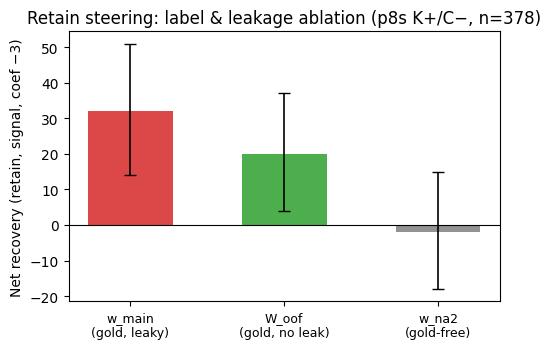

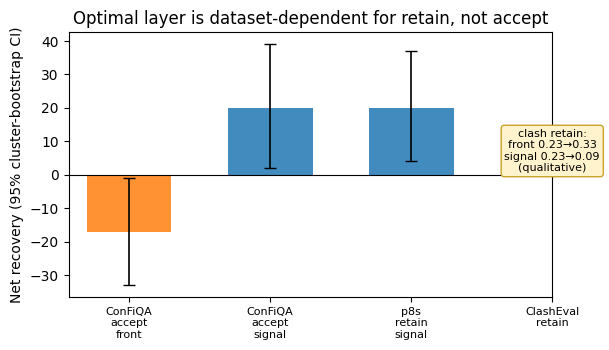

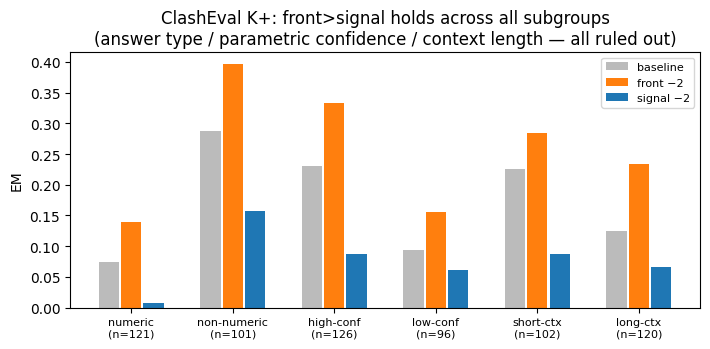

저장: /content/drive/MyDrive/Grad_share/data_share/P9/figs


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

FIG_DIR = f"{SAVE_DIR}/figs"; import os; os.makedirs(FIG_DIR, exist_ok=True)

def net_ci(base, cur, groups):
    r = cluster_bootstrap(base, cur, groups)
    return r["net_mean"], r["net_CI"]

# ══ Fig 1. Gold-free × leakage — 오늘의 핵심 반전 ══
g_ret = pairs9.loc[kp_idx, "question"].values
na2 = np.load(f"{P9}/steer_na2_ckpt.npz")
conds = [
    ("w_main\n(gold, leaky)",  "#d62728", 32, (14, 51)),                 # 기록값
    ("W_oof\n(gold, no leak)", "#2ca02c", *net_ci(oof[0], oof[-3], g_ret)),
    ("w_na2\n(gold-free)",     "#7f7f7f", *net_ci(na2["retain_0"], na2["retain_-3"], g_ret)),
]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
for i, (lab, c, m, ci) in enumerate(conds):
    ax.bar(i, m, color=c, width=0.55, alpha=0.85)
    ax.errorbar(i, m, yerr=[[m-ci[0]], [ci[1]-m]], color="k", capsize=4, lw=1.2)
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(range(3)); ax.set_xticklabels([c[0] for c in conds], fontsize=9)
ax.set_ylabel("Net recovery (retain, signal, coef −3)")
ax.set_title("Retain steering: label & leakage ablation (p8s K+/C−, n=378)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_goldfree_leakage.png", dpi=150); plt.show()

# ══ Fig 2. Layer × dataset — 유의성 지도 ══
g_cf = sv.question.values[W_OOF["confiqa"][0]]
b_cf = res_sv[('confiqa','base','0')]
rows = [  # (label, block, mean, ci, direction)
    ("ConFiQA\naccept",  "front",  *net_ci(b_cf, res_sv[('confiqa','front','3')],  g_cf)),
    ("ConFiQA\naccept",  "signal", *net_ci(b_cf, res_sv[('confiqa','signal','3')], g_cf)),
    ("p8s\nretain",      "signal", *net_ci(oof[0], oof[-3], g_ret)),
]
fig, ax = plt.subplots(figsize=(6.2, 3.6))
x, ticks = 0, []
for lab, blk, m, ci in rows:
    col = "#1f77b4" if blk == "signal" else "#ff7f0e"
    ax.bar(x, m, color=col, width=0.6, alpha=0.85)
    ax.errorbar(x, m, yerr=[[m-ci[0]], [ci[1]-m]], color="k", capsize=4, lw=1.2)
    ticks.append(f"{lab}\n{blk}"); x += 1
# clash: CI 미산출(정성 재현) → EM 표기 막대 대신 텍스트 패널
ax.bar(x, 0, width=0)  # 자리
ax.text(x, 1, "clash retain:\nfront 0.23→0.33\nsignal 0.23→0.09\n(qualitative)", ha="center", fontsize=8,
        bbox=dict(boxstyle="round", fc="#fff3cd", ec="#c9a227"))
ticks.append("ClashEval\nretain")
ax.axhline(0, c="k", lw=0.8)
ax.set_xticks(range(x+1)); ax.set_xticklabels(ticks, fontsize=8)
ax.set_ylabel("Net recovery (95% cluster-bootstrap CI)")
ax.set_title("Optimal layer is dataset-dependent for retain, not accept")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_layer_dataset.png", dpi=150); plt.show()

# ══ Fig 3. 소거 3종 — clash K+ 내부 분해 ══
# 오늘 CPU 분해에서 나온 값 (front−2 / signal−2 EM, baseline 포함)
sub = {  # group: (n, base, front-2, signal-2)
    "numeric":      (121, 0.074, 0.140, 0.008),
    "non-numeric":  (101, 0.287, 0.396, 0.158),
    "high-conf":    (126, 0.230, 0.333, 0.087),
    "low-conf":     ( 96, 0.094, 0.156, 0.062),
    "short-ctx":    (102, 0.225, 0.284, 0.088),
    "long-ctx":     (120, 0.125, 0.233, 0.067),
}
fig, ax = plt.subplots(figsize=(7.2, 3.6))
labs = list(sub); xs = np.arange(len(labs))
for off, key, col, name in [(-0.22, 1, "#bbbbbb", "baseline"),
                            (0.0,   2, "#ff7f0e", "front −2"),
                            (0.22,  3, "#1f77b4", "signal −2")]:
    ax.bar(xs+off, [sub[l][key] for l in labs], width=0.2, color=col, label=name)
ax.set_xticks(xs); ax.set_xticklabels([f"{l}\n(n={sub[l][0]})" for l in labs], fontsize=8)
ax.set_ylabel("EM"); ax.legend(fontsize=8)
ax.set_title("ClashEval K+: front>signal holds across all subgroups\n(answer type / parametric confidence / context length — all ruled out)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_elimination.png", dpi=150); plt.show()
print("저장:", FIG_DIR)

In [ ]:
w_na = np.load(f"{P9}/w_behavior_na.npy").astype(np.float32)
c = cos_layers(w_na, np.load(f"{P9}/w_behavior_na2.npy"))
print("cos(w_na, w_na2) L14-18:", [round(float(c[L-1]),3) for L in [14,15,16,17,18]])

for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear()
w_t.copy_(torch.tensor(w_na, device=model.device, dtype=torch.bfloat16))
attach()
_cfg["coef"], _cfg["layers"] = -3, [14,15,16,17,18]
ems=[]
for i in tqdm(kp_idx, desc="na-3", leave=False):
    r = pairs9.loc[i]
    enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
    L = enc["input_ids"].shape[1]
    g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
    ems.append(em(tok.decode(g[0,L:], skip_special_tokens=True).strip(), r.gold))
detach()
na_m3 = np.array(ems)
np.save(f"{P9}/retain_na_m3.npy", na_m3)

b = oof[0]   # baseline은 무개입이라 w와 무관 — 재사용
rec=((b==0)&(na_m3==1)).sum(); brk=((b==1)&(na_m3==0)).sum()
rb = cluster_bootstrap(b, na_m3, g_ret)
print(f"\n[w_na signal −3] EM {na_m3.mean():.3f} 회복 {rec} 손상 {brk} 순증 {rec-brk:+} CI{rb['net_CI']}")
print("[참조] W_oof(gold): +20 [4,37] | w_na2(확장정규식): −3")

cos(w_na, w_na2) L14-18: [0.94, 0.921, 0.922, 0.899, 0.892]


na-3:   0%|          | 0/378 [00:00<?, ?it/s]


[w_na signal −3] EM 0.450 회복 41 손상 44 순증 -3 CI(np.float64(-21.0), np.float64(15.0))
[참조] W_oof(gold): +20 [4,37] | w_na2(확장정규식): −3


https://claude.ai/public/artifacts/b599fab4-bae9-40ee-99fa-2251c196a3c5

# Steering train/val 분리 + 데이터셋 구분
- 목적: 클러스터링에서 사용한 벤치마크로 layer 효과의 일관성 확인
- 교수님 질문: 데이터셋이 달라지면 steering 효과도 달라지는가?

**설계 시 주의점**

(a) strat_v2에는 C+가 없음. 전부 counterfactual substitution이라 K−/C+ 셀이 성립하지 않음. → accept 방향은 이 데이터셋에서 검증 불가, retain 방향(K+/C−)만 가능. 보고 시 "두 방향 모두 확인"이 아니라 범위를 명시할 것.

(b) w를 벤치마크별로 재추정해야 함. P9의 w를 그대로 쓰면 "데이터셋이 달라지면 layer가 달라지나"가 아니라 "P9 w가 다른 데이터에 전이되나"를 측정하게 됨. → 벤치마크 내 train split에서 w 추정 → 같은 벤치마크 val split에서 steering.

**규모 (스크리닝, 최소 구성)**

- 벤치마크 4개 × block 3개(front/signal/late) × coef {0, −3} × val 150개 = 3,600 생성
- A100 50~70분 / L4 3~4시간

late block(L22–26)은 음성 대조군. 교수님 의견(L25–27은 아님)은 attention heatmap 기반 추정이며 실측이 아니므로, 대조군으로 포함해 두면 근거가 됨.

**전제 조건**: strat_v2에 answer_surface에 해당하는 컬럼(문맥이 주장하는 답)이 있어야 na2 라벨링이 가능. 컬럼명 사전 확인 필요.

|비교|	통제	|답하는 질문|
|---|---------|------------|
|confiqa vs nqswap (accept, K 고정)|	방향·K|	데이터셋이 바뀌면 layer가 바뀌나 ← 교수님 질문|
|clasheval K+ vs K− (reject)|	방향·데이터셋	|K±가 layer를 좌우하나 ← D 실험 교란|
|accept vs reject (K 고정)|	K	|role separation이 진짜 방향 효과인가|


- 세 번째 비교가 가장 중요. accept∩K+(confiqa 244 + nqswap 247 = 491)와 reject∩K+(222)를 비교하면 K를 고정한 채 방향만 바꾼 대조가 됨. 8/15 결과에서는 불가능했던 비교. 여기서도 accept↔mid / retain↔front가 나오면 role separation은 실제 효과, 사라지면 데이터셋 효과.

**설계 확정**
- w 추정: 각 조건 내부 train split에서 재추정 (P9 w 전이 아님)
- 평가: 같은 조건 val split, GroupKFold(question 단위)
- 블록: front[8–12], signal[14–18], late[22–26] — late는 음성 대조
- 라벨: v1(gold). gold-free는 별도 트랙
- 정답 기준: accept 셀 = contextual_answer, reject 셀 = parametric_answer

In [ ]:
K = sv.K_state3.str.startswith("K+").map({True:"K+",False:"K-"})
cells = {
 "A_confiqa_acc_K-": (sv.dataset_id=="confiqa_qa") & (sv.desired_action=="accept") & (K=="K-"),
 "B_nqswap_acc_K-" : (sv.dataset_id=="nqswap")     & (sv.desired_action=="accept") & (K=="K-"),
 "C_confiqa_acc_K+": (sv.dataset_id=="confiqa_qa") & (sv.desired_action=="accept") & (K=="K+"),
 "D_clash_rej_K+"  : (sv.dataset_id=="clasheval")  & (sv.desired_action=="reject") & (K=="K+"),
 "E_clash_rej_K-"  : (sv.dataset_id=="clasheval")  & (sv.desired_action=="reject") & (K=="K-"),
}
print(sv.behavior.value_counts().to_dict(), "\n")
for k, m in cells.items():
    print(f"{k:20} n={m.sum():4}", sv[m].behavior.value_counts().to_dict())

{'accepted_context': 846, 'both': 352, 'retained_parametric': 323, 'other': 264, 'abstain': 131} 

A_confiqa_acc_K-     n= 236 {'accepted_context': 129, 'other': 42, 'abstain': 27, 'both': 20, 'retained_parametric': 18}
B_nqswap_acc_K-      n= 230 {'accepted_context': 110, 'other': 55, 'retained_parametric': 29, 'both': 27, 'abstain': 9}
C_confiqa_acc_K+     n= 244 {'both': 108, 'retained_parametric': 60, 'accepted_context': 49, 'other': 15, 'abstain': 12}
D_clash_rej_K+       n= 222 {'accepted_context': 124, 'retained_parametric': 46, 'both': 24, 'abstain': 15, 'other': 13}
E_clash_rej_K-       n= 258 {'accepted_context': 162, 'other': 43, 'abstain': 28, 'retained_parametric': 17, 'both': 8}


설계 변경 — w를 셀별이 아니라 pooled OOF로

In [ ]:
K = sv.K_state3.str.startswith("K+").map({True:"K+",False:"K-"})
ACC, RET = "accepted_context", "retained_parametric"

def w_of(mask):
    m = mask & sv.behavior.isin([ACC,RET])
    idx = np.where(m)[0]
    lab = sv.behavior.values[idx]
    return diff_of_means(HSV[idx], lab==ACC, lab==RET), (lab==ACC).sum(), (lab==RET).sum()

groups = {
 "confiqa": sv.dataset_id=="confiqa_qa",
 "nqswap" : sv.dataset_id=="nqswap",
 "clash"  : sv.dataset_id=="clasheval",
 "K+"     : K=="K+",
 "K-"     : K=="K-",
}
Ws = {}
for k,m in groups.items():
    Ws[k], na, nr = w_of(m); print(f"{k:8} acc={na:4} ret={nr:4}")

names = list(Ws)
for L in [10,12,15,16,18]:
    print(f"\n--- L{L} ---")
    for i in range(len(names)):
        for j in range(i+1,len(names)):
            c = cos_layers(Ws[names[i]], Ws[names[j]])[L-1]
            print(f"  {names[i]:8} vs {names[j]:8} {c:.3f}")

confiqa  acc= 178 ret=  78
nqswap   acc= 180 ret= 104
clash    acc= 286 ret=  63
K+       acc= 322 ret= 240
K-       acc= 524 ret=  83

--- L10 ---
  confiqa  vs nqswap   0.198
  confiqa  vs clash    -0.147
  confiqa  vs K+       0.115
  confiqa  vs K-       0.293
  nqswap   vs clash    0.009
  nqswap   vs K+       0.237
  nqswap   vs K-       0.187
  clash    vs K+       0.616
  clash    vs K-       0.386
  K+       vs K-       0.545

--- L12 ---
  confiqa  vs nqswap   0.298
  confiqa  vs clash    -0.018
  confiqa  vs K+       0.288
  confiqa  vs K-       0.526
  nqswap   vs clash    0.008
  nqswap   vs K+       0.314
  nqswap   vs K-       0.288
  clash    vs K+       0.603
  clash    vs K-       0.377
  K+       vs K-       0.578

--- L15 ---
  confiqa  vs nqswap   0.408
  confiqa  vs clash    0.233
  confiqa  vs K+       0.581
  confiqa  vs K-       0.721
  nqswap   vs clash    0.236
  nqswap   vs K+       0.521
  nqswap   vs K-       0.478
  clash    vs K+       0.690
  clash    v

(1) 방향은 데이터셋 불변이 아님. "conflict를 처리하는 단일 방향"이라는 전제가 strat_v2에서는 성립하지 않음.

(2) K±로 묶으면 정렬이 크게 개선됨. K+ vs K−가 L16에서 0.803, clash vs K+가 0.751. 즉 데이터셋보다 K±가 방향을 더 잘 설명함.

In [ ]:
def w_idx(idx):
    lab = sv.behavior.values[idx]
    m = np.isin(lab, [ACC, RET])
    return diff_of_means(HSV[idx[m]], lab[m]==ACC, lab[m]==RET)

def split_half_cos(mask, n_rep=20, seed=0):
    rng = np.random.default_rng(seed)
    idx = np.where(mask & sv.behavior.isin([ACC,RET]))[0]
    q = sv.question.values[idx]
    uq = np.unique(q)
    out = []
    for _ in range(n_rep):
        perm = rng.permutation(uq)
        h1 = np.isin(q, perm[:len(uq)//2])
        try:    out.append(cos_layers(w_idx(idx[h1]), w_idx(idx[~h1])))
        except: pass
    return np.array(out)

for name, m in [("confiqa", sv.dataset_id=="confiqa_qa"),
                ("nqswap",  sv.dataset_id=="nqswap"),
                ("clash",   sv.dataset_id=="clasheval")]:
    C = split_half_cos(m)
    print(name, {f"L{L}": round(float(np.median(C[:,L-1])),3) for L in [10,12,15,16,18]})

confiqa {'L10': 0.691, 'L12': 0.775, 'L15': 0.815, 'L16': 0.834, 'L18': 0.833}
nqswap {'L10': 0.177, 'L12': 0.232, 'L15': 0.383, 'L16': 0.536, 'L18': 0.504}
clash {'L10': 0.856, 'L12': 0.821, 'L15': 0.829, 'L16': 0.851, 'L18': 0.872}


In [ ]:
K = sv.K_state3.str.startswith("K+").map({True:"K+",False:"K-"})
sub = {
 "confiqa_K+": (sv.dataset_id=="confiqa_qa") & (K=="K+"),   # acc49 ret60
 "clash_K+"  : (sv.dataset_id=="clasheval")  & (K=="K+"),   # acc124 ret46
}
Wk = {k: w_of(m)[0] for k,m in sub.items()}
c = cos_layers(Wk["confiqa_K+"], Wk["clash_K+"])
print("confiqa_K+ vs clash_K+:", {f"L{L}": round(float(c[L-1]),3) for L in [10,12,15,16,18]})
for k,m in sub.items():
    C = split_half_cos(m)
    print(f"  {k} 노이즈바닥:", {f"L{L}": round(float(np.median(C[:,L-1])),3) for L in [10,12,15,16,18]})

confiqa_K+ vs clash_K+: {'L10': -0.192, 'L12': -0.067, 'L15': 0.224, 'L16': 0.249, 'L18': 0.236}
  confiqa_K+ 노이즈바닥: {'L10': 0.551, 'L12': 0.607, 'L15': 0.655, 'L16': 0.681, 'L18': 0.686}
  clash_K+ 노이즈바닥: {'L10': 0.87, 'L12': 0.854, 'L15': 0.835, 'L16': 0.846, 'L18': 0.867}


In [ ]:
from sklearn.model_selection import GroupKFold
ACC, RET = "accepted_context", "retained_parametric"

DS = {"confiqa": ("confiqa_qa", "contextual_answer", [ 2,  3]),
      "clash"  : ("clasheval",  "parametric_answer", [-2, -3])}
BLOCKS = {"front":[8,9,10,11,12], "signal":[14,15,16,17,18]}

# ── 데이터셋별 OOF w (질문 단위, 누수 0) ──
W_OOF = {}
for name,(did,_,_) in DS.items():
    ridx = np.where((sv.dataset_id==did).values)[0]
    q = sv.question.values[ridx]
    Wf = np.zeros((len(ridx), 32, 4096), dtype=np.float32)
    for tr, te in GroupKFold(5).split(ridx, groups=q):
        gi  = ridx[tr]
        lab = sv.behavior.values[gi]
        m   = np.isin(lab, [ACC, RET])
        Wf[te] = diff_of_means(HSV[gi[m]], lab[m]==ACC, lab[m]==RET)
    W_OOF[name] = (ridx, Wf)
    print(name, "OOF w:", Wf.shape)

# ── steering ──
@torch.no_grad()
def run_ds(name, block, coef):
    ridx, Wf = W_OOF[name]
    _, tgtcol, _ = DS[name]
    _cfg["coef"], _cfg["layers"] = coef, block
    out = []
    for j, i in enumerate(ridx):
        r = sv.iloc[i]
        w_t.copy_(torch.tensor(Wf[j], device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        a = tok.decode(g[0,L:], skip_special_tokens=True).strip()
        out.append(int(match_gold(a, [r[tgtcol]])))
    return np.array(out)

attach(); res = {}
for name,(_,_,coefs) in DS.items():
    res[(name,"base",0)] = run_ds(name, [], 0)
    for bn, blk in BLOCKS.items():
        for c in tqdm(coefs, desc=f"{name}-{bn}"):
            res[(name,bn,c)] = run_ds(name, blk, c)
detach()

for name,(_,_,coefs) in DS.items():
    base = res[(name,"base",0)]
    print(f"\n[{name}] baseline EM {base.mean():.3f}  n={len(base)}")
    for bn in BLOCKS:
        for c in coefs:
            cur = res[(name,bn,c)]
            rec = ((base==0)&(cur==1)).sum(); brk = ((base==1)&(cur==0)).sum()
            print(f"  {bn:7} coef{c:+}: EM {cur.mean():.3f} 회복 {rec:3} 손상 {brk:3} 순증 {rec-brk:+4}")
np.savez(f"{SAVE_DIR}/sv_layer_sweep.npz", **{f"{a}_{b}_{c}":v for (a,b,c),v in res.items()})

confiqa OOF w: (480, 32, 4096)
clash OOF w: (480, 32, 4096)


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


confiqa-front:   0%|          | 0/2 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
b = res[('confiqa','base',0)]
print("confiqa baseline EM:", b.mean().round(3), "n =", len(b))

confiqa baseline EM: 0.738 n = 480


In [ ]:
res = {('confiqa','base','0'): res[('confiqa','base',0)]}

In [ ]:
import os
CKPT = f"{SAVE_DIR}/sv_layer_ckpt.npz"
np.savez(CKPT, **{"|".join(k): v for k, v in res.items()})
print("보존:", list(res.keys()))

@torch.no_grad()
def run_ds(name, block, coef, key):
    if key in res:
        print("skip", key); return res[key]
    ridx, Wf = W_OOF[name]
    _, tgtcol, _ = DS[name]
    _cfg["coef"], _cfg["layers"] = coef, block
    out = []
    for j, i in enumerate(tqdm(ridx, desc="|".join(key), leave=False)):
        r = sv.iloc[i]
        w_t.copy_(torch.tensor(Wf[j], device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(int(match_gold(tok.decode(g[0,L:], skip_special_tokens=True).strip(), [r[tgtcol]])))
    res[key] = np.array(out)
    np.savez(CKPT, **{"|".join(k): v for k, v in res.items()})
    return res[key]

attach()
for name,(_,_,coefs) in DS.items():
    run_ds(name, [], 0, (name,"base","0"))
    for bn, blk in BLOCKS.items():
        for c in coefs:
            run_ds(name, blk, c, (name,bn,str(c)))
detach()
print("\n전체 완료:", len(res), "config")

보존: [('confiqa', 'base', '0')]
skip ('confiqa', 'base', '0')


confiqa|front|2:   0%|          | 0/480 [00:00<?, ?it/s]

confiqa|front|3:   0%|          | 0/480 [00:00<?, ?it/s]

confiqa|signal|2:   0%|          | 0/480 [00:00<?, ?it/s]

confiqa|signal|3:   0%|          | 0/480 [00:00<?, ?it/s]

...

clash|front|-2:   0%|          | 0/480 [00:00<?, ?it/s]

clash|front|-3:   0%|          | 0/480 [00:00<?, ?it/s]

clash|signal|-2:   0%|          | 0/480 [00:00<?, ?it/s]

clash|signal|-3:   0%|          | 0/480 [00:00<?, ?it/s]


전체 완료: 10 config


In [ ]:
for name,(_,_,coefs) in DS.items():
    base = res[(name,'base','0')]
    print(f"\n[{name}] baseline EM {base.mean():.3f}  n={len(base)}  (틀린 것 {(base==0).sum()})")
    for bn in BLOCKS:
        for c in coefs:
            cur = res[(name,bn,str(c))]
            rec = ((base==0)&(cur==1)).sum(); brk = ((base==1)&(cur==0)).sum()
            print(f"  {bn:7} coef{c:+}: EM {cur.mean():.3f} 회복 {rec:3} ({rec/max((base==0).sum(),1):5.1%}) "
                  f"손상 {brk:3} 순증 {rec-brk:+4}")


[confiqa] baseline EM 0.738  n=480  (틀린 것 126)
  front   coef+2: EM 0.715 회복  19 (15.1%) 손상  30 순증  -11
  front   coef+3: EM 0.702 회복  25 (19.8%) 손상  42 순증  -17
  signal  coef+2: EM 0.752 회복  38 (30.2%) 손상  31 순증   +7
  signal  coef+3: EM 0.779 회복  53 (42.1%) 손상  33 순증  +20

[clash] baseline EM 0.160  n=480  (틀린 것 403)
  front   coef-2: EM 0.150 회복   7 ( 1.7%) 손상  12 순증   -5
  front   coef-3: EM 0.156 회복  11 ( 2.7%) 손상  13 순증   -2
  signal  coef-2: EM 0.163 회복  19 ( 4.7%) 손상  18 순증   +1
  signal  coef-3: EM 0.150 회복  17 ( 4.2%) 손상  22 순증   -5


In [ ]:
K = sv.K_state3.str.startswith("K+").values
ridx = W_OOF["clash"][0]
kmask = K[ridx]
base = res[('clash','base','0')]

for tag, m in [("K+", kmask), ("K-", ~kmask)]:
    b = base[m]
    print(f"\n[clash {tag}] n={m.sum()} baseline EM {b.mean():.3f} (틀린 것 {(b==0).sum()})")
    for bn in ["front","signal"]:
        for c in [-2,-3]:
            cur = res[('clash',bn,str(c))][m]
            rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
            print(f"  {bn:7} {c}: EM {cur.mean():.3f} 회복 {rec:3} ({rec/max((b==0).sum(),1):5.1%}) 손상 {brk:3} 순증 {rec-brk:+4}")


[clash K+] n=222 baseline EM 0.243 (틀린 것 168)
  front   -2: EM 0.243 회복   6 ( 3.6%) 손상   6 순증   +0
  front   -3: EM 0.234 회복   7 ( 4.2%) 손상   9 순증   -2
  signal  -2: EM 0.257 회복  14 ( 8.3%) 손상  11 순증   +3
  signal  -3: EM 0.243 회복  12 ( 7.1%) 손상  12 순증   +0

[clash K-] n=258 baseline EM 0.089 (틀린 것 235)
  front   -2: EM 0.070 회복   1 ( 0.4%) 손상   6 순증   -5
  front   -3: EM 0.089 회복   4 ( 1.7%) 손상   4 순증   +0
  signal  -2: EM 0.081 회복   5 ( 2.1%) 손상   7 순증   -2
  signal  -3: EM 0.070 회복   5 ( 2.1%) 손상  10 순증   -5


In [ ]:
ACC, RET = "accepted_context", "retained_parametric"
K = sv.K_state3.str.startswith("K+").values

# strat_v2 전체 OOF w (질문 단위)
allm = sv.behavior.isin([ACC,RET]).values
aidx = np.where(allm)[0]
W_all = np.zeros((len(sv), 32, 4096), dtype=np.float32)
for tr, te in GroupKFold(5).split(np.arange(len(sv)), groups=sv.question.values):
    gi  = np.intersect1d(tr, aidx)
    lab = sv.behavior.values[gi]
    W_all[te] = diff_of_means(HSV[gi], lab==ACC, lab==RET)

# 8/15와 동일한 평가셀
ev = np.where((sv.dataset_id=="clasheval").values & K)[0]
print("n =", len(ev))
c = cos_layers(W_all[ev[0]], W_OOF["clash"][1][0])
print("pooled vs clash-only w:", {f"L{L}": round(float(c[L-1]),3) for L in [10,12,15,16,18]})

@torch.no_grad()
def run_pooled(block, coef):
    _cfg["coef"], _cfg["layers"] = coef, block
    out=[]
    for i in tqdm(ev, desc=f"pooled{coef}", leave=False):
        r = sv.iloc[i]
        w_t.copy_(torch.tensor(W_all[i], device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(int(match_gold(tok.decode(g[0,L:], skip_special_tokens=True).strip(),
                                  [r.parametric_answer])))
    return np.array(out)

attach(); pres={}
for bn, blk in BLOCKS.items():
    for cf in [-2,-3]:
        pres[(bn,cf)] = run_pooled(blk, cf)
detach()

b = res[('clash','base','0')][K[W_OOF["clash"][0]]]
print(f"\nbaseline EM {b.mean():.3f} (틀린 것 {(b==0).sum()})")
print("[8/15 참조] front−2: EM 0.207→0.477\n")
for (bn,cf), cur in pres.items():
    rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
    print(f"  {bn:7} {cf}: EM {cur.mean():.3f} 회복 {rec:3} 손상 {brk:3} 순증 {rec-brk:+4}")

n = 222
pooled vs clash-only w: {'L10': 0.609, 'L12': 0.548, 'L15': 0.694, 'L16': 0.767, 'L18': 0.813}


pooled-2:   0%|          | 0/222 [00:00<?, ?it/s]

pooled-3:   0%|          | 0/222 [00:00<?, ?it/s]

pooled-2:   0%|          | 0/222 [00:00<?, ?it/s]

pooled-3:   0%|          | 0/222 [00:00<?, ?it/s]


baseline EM 0.243 (틀린 것 168)
[8/15 참조] front−2: EM 0.207→0.477

  front   -2: EM 0.248 회복   7 손상   6 순증   +1
  front   -3: EM 0.243 회복   7 손상   7 순증   +0
  signal  -2: EM 0.266 회복  10 손상   5 순증   +5
  signal  -3: EM 0.284 회복  18 손상   9 순증   +9


In [ ]:
import re
def find_num(t, a):
    a = str(a).strip()
    if re.fullmatch(r"[\d.,]+", a):
        return re.search(rf"(?<!\d){re.escape(a)}(?!\d)", t) is not None
    return re.search(rf"(?<!\w){re.escape(a)}(?!\w)", t, re.I) is not None

def em_815(t, para, ctx, goal):
    hp, hx = find_num(t, str(para)), find_num(t, str(ctx))
    if hp and not hx: return int(goal == "reject")
    if hx and not hp: return int(goal == "accept")
    return 0

# w·σ를 8/15 방식으로: 평가셀 제외 + 투영 std를 벡터에 곱해 저장
def build_V(block, ds):
    ev = np.where((sv.dataset_id == ds).values)[0]
    tr = np.ones(len(sv), bool); tr[ev] = False
    tr &= sv.behavior.isin([ACC, RET]).values
    Vd = {}
    for L in block:
        X = layer(HSV, L)
        w = X[tr & (sv.behavior == ACC).values].mean(0) - X[tr & (sv.behavior == RET).values].mean(0)
        w /= np.linalg.norm(w)
        sig = (X[tr] @ w).std()
        Vd[L] = torch.tensor(w * sig, dtype=torch.bfloat16, device=model.device)
    return Vd, ev

def sweep_815(ds, block, coefs):
    Vd, ev = build_V(block, ds)
    hs = [model.model.layers[L].register_forward_hook(
            (lambda v: lambda m,i,o: ((o[0]+_c["v"]*v,)+o[1:]) if isinstance(o,tuple)
                                      else o+_c["v"]*v)(Vd[L])) for L in block]
    out = {}
    for c in coefs:
        _c["v"] = c; ems = []
        for i in tqdm(ev, desc=f"{ds}{c}", leave=False):
            r = sv.iloc[i]
            enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
            L0 = enc["input_ids"].shape[1]
            g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
            t = tok.decode(g[0, L0:], skip_special_tokens=True).strip()
            ems.append(em_815(t, r.parametric_answer, r.contextual_answer, r.desired_action))
        out[c] = np.array(ems)
    _c["v"] = 0.0
    for h in hs: h.remove()
    return out

_c = {"v": 0.0}
for lyr in model.model.layers: lyr._forward_hooks.clear()

r_front = sweep_815("clasheval", [8,9,10,11,12], [0,-1.5,-2])
r_sig   = sweep_815("clasheval", [14,15,16,17,18], [-2])
print("[8/15 참조] front−2: 0.207→0.477 | mid−2: 0.149\n")
for tag, d in [("front", r_front), ("signal", r_sig)]:
    for c, v in d.items(): print(f"  {tag:7} {c}: EM {v.mean():.3f}")

clasheval0:   0%|          | 0/480 [00:00<?, ?it/s]

clasheval-1.5:   0%|          | 0/480 [00:00<?, ?it/s]

clasheval-2:   0%|          | 0/480 [00:00<?, ?it/s]

clasheval-2:   0%|          | 0/480 [00:00<?, ?it/s]

[8/15 참조] front−2: 0.207→0.477 | mid−2: 0.149

  front   0: EM 0.106
  front   -1.5: EM 0.119
  front   -2: EM 0.152
  signal  -2: EM 0.044


In [ ]:
K = sv.K_state3.str.startswith("K+").values
ev = np.where((sv.dataset_id=="clasheval").values)[0]
kp = K[ev]
for tag, d in [("front", r_front), ("signal", r_sig)]:
    for c, v in d.items():
        print(f"{tag:7} {c:+}: K+ EM {v[kp].mean():.3f} (n={kp.sum()}) | K- EM {v[~kp].mean():.3f}")

front   +0: K+ EM 0.171 (n=222) | K- EM 0.050
front   -1.5: K+ EM 0.203 (n=222) | K- EM 0.047
front   -2: K+ EM 0.257 (n=222) | K- EM 0.062
signal  -2: K+ EM 0.077 (n=222) | K- EM 0.016


In [ ]:
import re
def is_num(a): return bool(re.fullmatch(r"[\d.,\s%]+", str(a).strip()))

# 1) 유형 구성 확인
for name, df, col in [("clash", sv[sv.dataset_id=="clasheval"], "parametric_answer"),
                      ("confiqa", sv[sv.dataset_id=="confiqa_qa"], "contextual_answer")]:
    n = df[col].apply(is_num)
    print(f"{name}: 수치 {n.sum()} / 비수치 {(~n).sum()}")

# 2) 오늘 재실행 배열을 유형별로 쪼개기 (clash K+)
ev = np.where((sv.dataset_id=="clasheval").values)[0]
kp = K[ev]
numeric = sv.iloc[ev].parametric_answer.apply(is_num).values
for tag, d in [("front", r_front), ("signal", r_sig)]:
    for c, v in d.items():
        m1 = kp & numeric; m2 = kp & ~numeric
        print(f"{tag:7} {c:+}: 수치 EM {v[m1].mean():.3f} (n={m1.sum()}) | "
              f"비수치 EM {v[m2].mean():.3f} (n={m2.sum()})")

clash: 수치 308 / 비수치 172
confiqa: 수치 0 / 비수치 480
front   +0: 수치 EM 0.074 (n=121) | 비수치 EM 0.287 (n=101)
front   -1.5: 수치 EM 0.083 (n=121) | 비수치 EM 0.347 (n=101)
front   -2: 수치 EM 0.140 (n=121) | 비수치 EM 0.396 (n=101)
signal  -2: 수치 EM 0.008 (n=121) | 비수치 EM 0.158 (n=101)


In [ ]:
ev = np.where((sv.dataset_id=="clasheval").values)[0]
kp = K[ev]
strong = (sv.iloc[ev].n_known5 == 5).values      # 확신 강함
for tag, d in [("front", r_front), ("signal", r_sig)]:
    for c, v in d.items():
        m1 = kp & strong; m2 = kp & ~strong
        b1 = r_front[0][m1] if 0 in r_front else None
        print(f"{tag:7} {c:+}: 확신강 EM {v[m1].mean():.3f} (n={m1.sum()}) | "
              f"확신약 EM {v[m2].mean():.3f} (n={m2.sum()})")

front   +0: 확신강 EM 0.230 (n=126) | 확신약 EM 0.094 (n=96)
front   -1.5: 확신강 EM 0.286 (n=126) | 확신약 EM 0.094 (n=96)
front   -2: 확신강 EM 0.333 (n=126) | 확신약 EM 0.156 (n=96)
signal  -2: 확신강 EM 0.087 (n=126) | 확신약 EM 0.062 (n=96)


In [ ]:
plen = sv.iloc[ev].prompt_len.values
short = kp & (plen < np.median(plen[kp]))
long_ = kp & ~short & kp
for tag, d in [("front", r_front), ("signal", r_sig)]:
    for c, v in d.items():
        print(f"{tag:7} {c:+}: 짧은지문 EM {v[short].mean():.3f} (n={short.sum()}) | "
              f"긴지문 EM {v[long_].mean():.3f} (n={long_.sum()})")

front   +0: 짧은지문 EM 0.225 (n=102) | 긴지문 EM 0.125 (n=120)
front   -1.5: 짧은지문 EM 0.216 (n=102) | 긴지문 EM 0.192 (n=120)
front   -2: 짧은지문 EM 0.284 (n=102) | 긴지문 EM 0.233 (n=120)
signal  -2: 짧은지문 EM 0.088 (n=102) | 긴지문 EM 0.067 (n=120)


# Steering에서 w 구하는 방법 구분

- accept인걸 또 밀면? retain인걸 또 밀면? : 범위 나눠서 밀면서 임계값이 어딨는지 파악하는 용도
- overhead가 얼마나 생기는가

## 새로운 데이터셋 + train/val

- 무조건 개입 검증 (accept subset alpha sweep) ← offline w로 고정한 상태에서

In [ ]:
# ── oracle w (전체 pooled) ──
ar9 = pairs9.behavior.isin(["accept","retain"]).values
lab_all = pairs9.behavior.values
w_oracle = diff_of_means(HID9[ar9], lab_all[ar9]=="accept", lab_all[ar9]=="retain")

# ── OOF w는 오늘 만든 W_oof 재사용 (전 행 커버) ──
acc_idx = pairs9[(pairs9.kside=="K−")&(pairs9.ctx_label=="C+")].index.values
print("행 겹침(oracle 추정∩평가):", len(set(np.where(ar9)[0]) & set(acc_idx)))   # 참고용
q_acc = pairs9.loc[acc_idx, "question"].values

@torch.no_grad()
def run_acc(idxs, get_w, coef):
    _cfg["coef"], _cfg["layers"] = coef, [14,15,16,17,18]
    out=[]
    for i in tqdm(idxs, desc=f"acc{coef}", leave=False):
        r = pairs9.loc[i]
        w_t.copy_(torch.tensor(get_w(i), device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        out.append(em(tok.decode(g[0,L:], skip_special_tokens=True).strip(), r.gold))
    return np.array(out)

for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()
split = {}
for name, gw in [("oracle", lambda i: w_oracle), ("oof", lambda i: W_oof[i])]:
    for c in [2, 3]:
        split[(name,c)] = run_acc(acc_idx, gw, c)
        np.savez(f"{P9}/acc_split.npz", **{f"{a}_{b}":v for (a,b),v in split.items()})
detach()

# ── 결과: baseline은 acc48['0'] 재사용 (coef 0은 w 무관) ──
b = acc48[0] if 0 in acc48 else np.load(f"{P9}/acc48.npz")["0"]
print(f"baseline EM {b.mean():.3f} (틀린 것 {(b==0).sum()} — 천장 주의)\n")
print(f"{'조건':>8} {'coef':>5} {'EM':>7} {'순증':>5} {'회복률':>7} {'CI':>12}")
for name in ["oracle","oof"]:
    for c in [2,3]:
        cur = split[(name,c)]
        rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
        rb = cluster_bootstrap(b, cur, q_acc)
        print(f"{name:>8} {c:>5} {cur.mean():>7.3f} {rec-brk:>+5} "
              f"{rec/max((b==0).sum(),1):>6.1%} {str(tuple(map(int,rb['net_CI']))):>12}")

행 겹침(oracle 추정∩평가): 203


acc2:   0%|          | 0/234 [00:00<?, ?it/s]

acc3:   0%|          | 0/234 [00:00<?, ?it/s]

acc2:   0%|          | 0/234 [00:00<?, ?it/s]

acc3:   0%|          | 0/234 [00:00<?, ?it/s]

baseline EM 0.868 (틀린 것 31 — 천장 주의)

      조건  coef      EM    순증     회복률           CI
  oracle     2   0.868    +0   9.7%      (-5, 5)
  oracle     3   0.880    +3  22.6%     (-3, 10)
     oof     2   0.868    +0   6.5%      (-4, 4)
     oof     3   0.876    +2  22.6%      (-4, 9)


In [ ]:
def collapsed(t):
    import re
    w=t.split()
    if len(w)>=8 and len(set(w))/len(w)<0.3: return True
    return re.search(r"(.{2,10})\1{3,}", t) is not None

@torch.no_grad()
def gen_one(i, coef, block):
    _cfg["coef"], _cfg["layers"] = coef, block
    r = pairs9.loc[i]
    w_t.copy_(torch.tensor(W_oof[i], device=model.device, dtype=torch.bfloat16))
    enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
    L = enc["input_ids"].shape[1]
    g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
    return tok.decode(g[0,L:], skip_special_tokens=True).strip()

FRONT, SIGNAL = [8,9,10,11,12], [14,15,16,17,18]
for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()

# ── (1) retain front OOF: signal 결과와 대조 ──
kp_idx = pairs9[(pairs9.kside=="K+")&(pairs9.ctx_label=="C-")].index.values
g_ret = pairs9.loc[kp_idx, "question"].values
ret_front = {}
for c in [0,-2,-3]:
    ems=[gen_one(i,c,FRONT) for i in tqdm(kp_idx, desc=f"retFront{c}", leave=False)]
    ret_front[c] = np.array([em(a, pairs9.loc[i].gold) for i,a in zip(kp_idx,ems)])
np.savez(f"{P9}/retain_front_oof.npz", **{str(k):v for k,v in ret_front.items()})

# ── (2)(3) accept 재-steering: baseline 성공 샘플을 더 밀기 ──
acc_idx = pairs9[(pairs9.kside=="K−")&(pairs9.ctx_label=="C+")].index.values
acc_base = acc48[0] if 0 in acc48 else np.load(f"{P9}/acc48.npz")["0"]
acc_ok = acc_idx[acc_base==1]
print("baseline accept 성공:", len(acc_ok))

push = {}
for tag, block in [("signal",SIGNAL), ("front",FRONT)]:
    for c in [0,1,2,3,5,8]:
        outs=[gen_one(i,c,block) for i in tqdm(acc_ok, desc=f"push-{tag}{c}", leave=False)]
        keep=np.array([em(a, pairs9.loc[i].gold) for i,a in zip(acc_ok,outs)])
        col=np.mean([collapsed(a) for a in outs])
        push[(tag,c)] = (keep, col)
detach()
np.savez(f"{P9}/accept_push.npz", **{f"{t}_{c}":v[0] for (t,c),v in push.items()})

# ── 결과 ──
print("\n=== (1) p8s retain: front vs signal (OOF, 48tok) ===")
b = ret_front[0]
for tag, d in [("front", ret_front), ("signal", {0:oof[0],-2:oof[-2],-3:oof[-3]})]:
    bb = d[0]
    for c in [-2,-3]:
        cur=d[c]; rec=((bb==0)&(cur==1)).sum(); brk=((bb==1)&(cur==0)).sum()
        rb=cluster_bootstrap(bb,cur,g_ret)
        print(f"  {tag:7} {c}: EM {cur.mean():.3f} 순증 {rec-brk:+} CI{tuple(map(int,rb['net_CI']))}")

print("\n=== (2)(3) accept 재-steering: 유지율 (임계값) ===")
print(f"{'block':>7} " + " ".join(f"c{c}" for c in [0,1,2,3,5,8]))
for tag in ["signal","front"]:
    keeps = " ".join(f"{push[(tag,c)][0].mean():.2f}" for c in [0,1,2,3,5,8])
    cols  = " ".join(f"{push[(tag,c)][1]:.2f}" for c in [0,1,2,3,5,8])
    print(f"{tag:>7} 유지 {keeps}")
    print(f"{'':>7} 붕괴 {cols}")

retFront0:   0%|          | 0/378 [00:00<?, ?it/s]

retFront-2:   0%|          | 0/378 [00:00<?, ?it/s]

retFront-3:   0%|          | 0/378 [00:00<?, ?it/s]

baseline accept 성공: 203


push-signal0:   0%|          | 0/203 [00:00<?, ?it/s]

...

push-front2:   0%|          | 0/203 [00:00<?, ?it/s]

push-front3:   0%|          | 0/203 [00:00<?, ?it/s]

push-front5:   0%|          | 0/203 [00:00<?, ?it/s]

push-front8:   0%|          | 0/203 [00:00<?, ?it/s]


=== (1) p8s retain: front vs signal (OOF, 48tok) ===
  front   -2: EM 0.463 순증 +2 CI(-7, 12)
  front   -3: EM 0.476 순증 +7 CI(-5, 20)
  signal  -2: EM 0.463 순증 +2 CI(-13, 18)
  signal  -3: EM 0.511 순증 +20 CI(4, 37)

=== (2)(3) accept 재-steering: 유지율 (임계값) ===
  block c0 c1 c2 c3 c5 c8
 signal 유지 1.00 0.99 0.99 0.98 0.97 0.97
        붕괴 0.00 0.00 0.00 0.00 0.00 0.00
  front 유지 1.00 0.99 0.99 0.99 0.99 0.99
        붕괴 0.00 0.00 0.00 0.00 0.00 0.00


In [ ]:
kp_idx = pairs9[(pairs9.kside=="K+")&(pairs9.ctx_label=="C-")].index.values
g_ret = pairs9.loc[kp_idx, "question"].values
b = oof[0]   # baseline 재사용 (coef 0)

for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()

ret_ext = {}
for c in [-4,-5,-8]:
    outs=[]
    for i in tqdm(kp_idx, desc=f"retExt{c}", leave=False):
        r = pairs9.loc[i]
        w_t.copy_(torch.tensor(W_oof[i], device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        outs.append(tok.decode(g[0,L:], skip_special_tokens=True).strip())
    ret_ext[c] = (np.array([em(a,pairs9.loc[i].gold) for i,a in zip(kp_idx,outs)]),
                  np.mean([collapsed(a) for a in outs]))
detach()
np.savez(f"{P9}/retain_ext.npz", **{str(k):v[0] for k,v in ret_ext.items()})

print("=== retain signal 강도 확장 (OOF, 48tok) ===")
print(f"  baseline EM {b.mean():.3f}")
print("  [기존] −2:+2  −3:+20[4,37]")
for c in [-4,-5,-8]:
    cur,col = ret_ext[c]
    rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
    rb=cluster_bootstrap(b,cur,g_ret)
    print(f"  {c}: EM {cur.mean():.3f} 순증 {rec-brk:+} CI{tuple(map(int,rb['net_CI']))} 붕괴 {col:.2f}")

retExt-4:   0%|          | 0/378 [00:00<?, ?it/s]

retExt-5:   0%|          | 0/378 [00:00<?, ?it/s]

retExt-8:   0%|          | 0/378 [00:00<?, ?it/s]

=== retain signal 강도 확장 (OOF, 48tok) ===
  baseline EM 0.458
  [기존] −2:+2  −3:+20[4,37]
  -4: EM 0.373 순증 -32 CI(-49, -16) 붕괴 0.00
  -5: EM 0.373 순증 -32 CI(-49, -16) 붕괴 0.00
  -8: EM 0.373 순증 -32 CI(-49, -16) 붕괴 0.00


In [ ]:
d = np.load(f"{P9}/retain_ext.npz")
print("배열 동일?", np.array_equal(d["-4"], d["-5"]), np.array_equal(d["-5"], d["-8"]))
# 실제 생성문 비교
for c in [-3,-4,-8]:
    _cfg["coef"], _cfg["layers"] = c, [14,15,16,17,18]
    i = kp_idx[0]; r = pairs9.loc[i]
    w_t.copy_(torch.tensor(W_oof[i], device=model.device, dtype=torch.bfloat16))
    enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
    L = enc["input_ids"].shape[1]
    g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
    print(f"coef{c}: {tok.decode(g[0,L:], skip_special_tokens=True).strip()[:100]}")

배열 동일? True True
coef-3: Action
coef-4: Action
coef-8: Action


In [ ]:
print("훅 개수:", sum(len(l._forward_hooks) for l in model.model.layers))

for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()
print("attach 후:", sum(len(l._forward_hooks) for l in model.model.layers))

i = kp_idx[0]; r = pairs9.loc[i]
print("gold:", r.gold, "| 문맥답:", r.answer_surface)
for c in [0, -3, -4, -8]:
    _cfg["coef"], _cfg["layers"] = c, [14,15,16,17,18]
    w_t.copy_(torch.tensor(W_oof[i], device=model.device, dtype=torch.bfloat16))
    enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
    L = enc["input_ids"].shape[1]
    g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
    print(f"coef{c:>3}: {tok.decode(g[0,L:], skip_special_tokens=True).strip()[:90]}")
detach()

훅 개수: 0
attach 후: 32
gold: ["Bollywood", "HFI", "HLFI", "Hindi language film industry", "Hindi Cinema", "HIFI"] | 문맥답: futurepop
coef  0: Action
coef -3: Action
coef -4: Action
coef -8: Action


In [ ]:
print("sig_t[13:18]:", sig_t[13:18].float().cpu().numpy().round(4))
print("w_t norm:", w_t.float().norm(dim=1)[13:18].cpu().numpy().round(3))
print("W_oof[i] norm:", np.linalg.norm(W_oof[kp_idx[0]], axis=1)[13:18].round(3))
print("_cfg:", _cfg)

sig_t[13:18]: [0.1055 0.1167 0.1318 0.1543 0.1719]
w_t norm: [1. 1. 1. 1. 1.]
W_oof[i] norm: [1. 1. 1. 1. 1.]
_cfg: {'coef': -8, 'layers': [14, 15, 16, 17, 18]}


In [ ]:
for lyr in model.model.layers: lyr._forward_hooks.clear()
_hooks.clear(); attach()

ret_ext = {}
for c in [-4,-5,-8]:
    _cfg["coef"], _cfg["layers"] = c, [14,15,16,17,18]   # ★ 누락됐던 줄
    outs=[]
    for i in tqdm(kp_idx, desc=f"retExt{c}", leave=False):
        r = pairs9.loc[i]
        w_t.copy_(torch.tensor(W_oof[i], device=model.device, dtype=torch.bfloat16))
        enc = tok(build_prompt_str(r), return_tensors="pt", add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=48, do_sample=False, pad_token_id=tok.pad_token_id)
        outs.append(tok.decode(g[0,L:], skip_special_tokens=True).strip())
    ret_ext[c] = (np.array([em(a, pairs9.loc[i].gold) for i,a in zip(kp_idx,outs)]),
                  np.mean([collapsed(a) for a in outs]))
    print(f"  {c} 완료: EM {ret_ext[c][0].mean():.3f}")   # config마다 즉시 확인
detach()
np.savez(f"{P9}/retain_ext.npz", **{str(k):v[0] for k,v in ret_ext.items()})

assert not np.array_equal(ret_ext[-4][0], ret_ext[-8][0]), "★ 배열 동일 — coef 미적용 의심"

b = oof[0]
print(f"\nbaseline EM {b.mean():.3f} | [기존] −2:+2  −3:+20[4,37]")
for c in [-4,-5,-8]:
    cur,col = ret_ext[c]
    rec=((b==0)&(cur==1)).sum(); brk=((b==1)&(cur==0)).sum()
    rb=cluster_bootstrap(b,cur,g_ret)
    print(f"  {c}: EM {cur.mean():.3f} 순증 {rec-brk:+} CI{tuple(map(int,rb['net_CI']))} 붕괴 {col:.2f}")

retExt-4:   0%|          | 0/378 [00:00<?, ?it/s]

  -4 완료: EM 0.503


retExt-5:   0%|          | 0/378 [00:00<?, ?it/s]

  -5 완료: EM 0.505


retExt-8:   0%|          | 0/378 [00:00<?, ?it/s]

  -8 완료: EM 0.442

baseline EM 0.458 | [기존] −2:+2  −3:+20[4,37]
  -4: EM 0.503 순증 +17 CI(1, 34) 붕괴 0.00
  -5: EM 0.505 순증 +18 CI(1, 36) 붕괴 0.00
  -8: EM 0.442 순증 -6 CI(-28, 14) 붕괴 0.00


## online
- 온라인 w + overhead/메모리 측정 ← overhead는 여기서 자동 병행